In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np

# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Separate features and target
data = housing.frame

# Display the first five rows
data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
data

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [3]:
print("Dataset shape:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nDataset information:")
data.info()

print("\nStatistical summary:")
data.describe()

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:
# Input features
X = data.drop("MedHouseVal", axis=1)

# Target variable
y = data["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget sample:")
print(y.head())

Features shape: (20640, 8)
Target shape: (20640,)

Feature columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target sample:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [5]:
# Check missing values in each column
print(data.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [6]:
# Count duplicate rows
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [7]:
# Display minimum and maximum values
print(data.agg(["min", "max"]).T)

                    min           max
MedInc         0.499900     15.000100
HouseAge       1.000000     52.000000
AveRooms       0.846154    141.909091
AveBedrms      0.333333     34.066667
Population     3.000000  35682.000000
AveOccup       0.692308   1243.333333
Latitude      32.540000     41.950000
Longitude   -124.350000   -114.310000
MedHouseVal    0.149990      5.000010


In [8]:
print("Target statistics:")
print(y.describe())

print("\nNumber of unique target values:", y.nunique())
print("Maximum target value:", y.max())

Target statistics:
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

Number of unique target values: 3842
Maximum target value: 5.00001


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent plotting style
sns.set_theme(style="whitegrid")

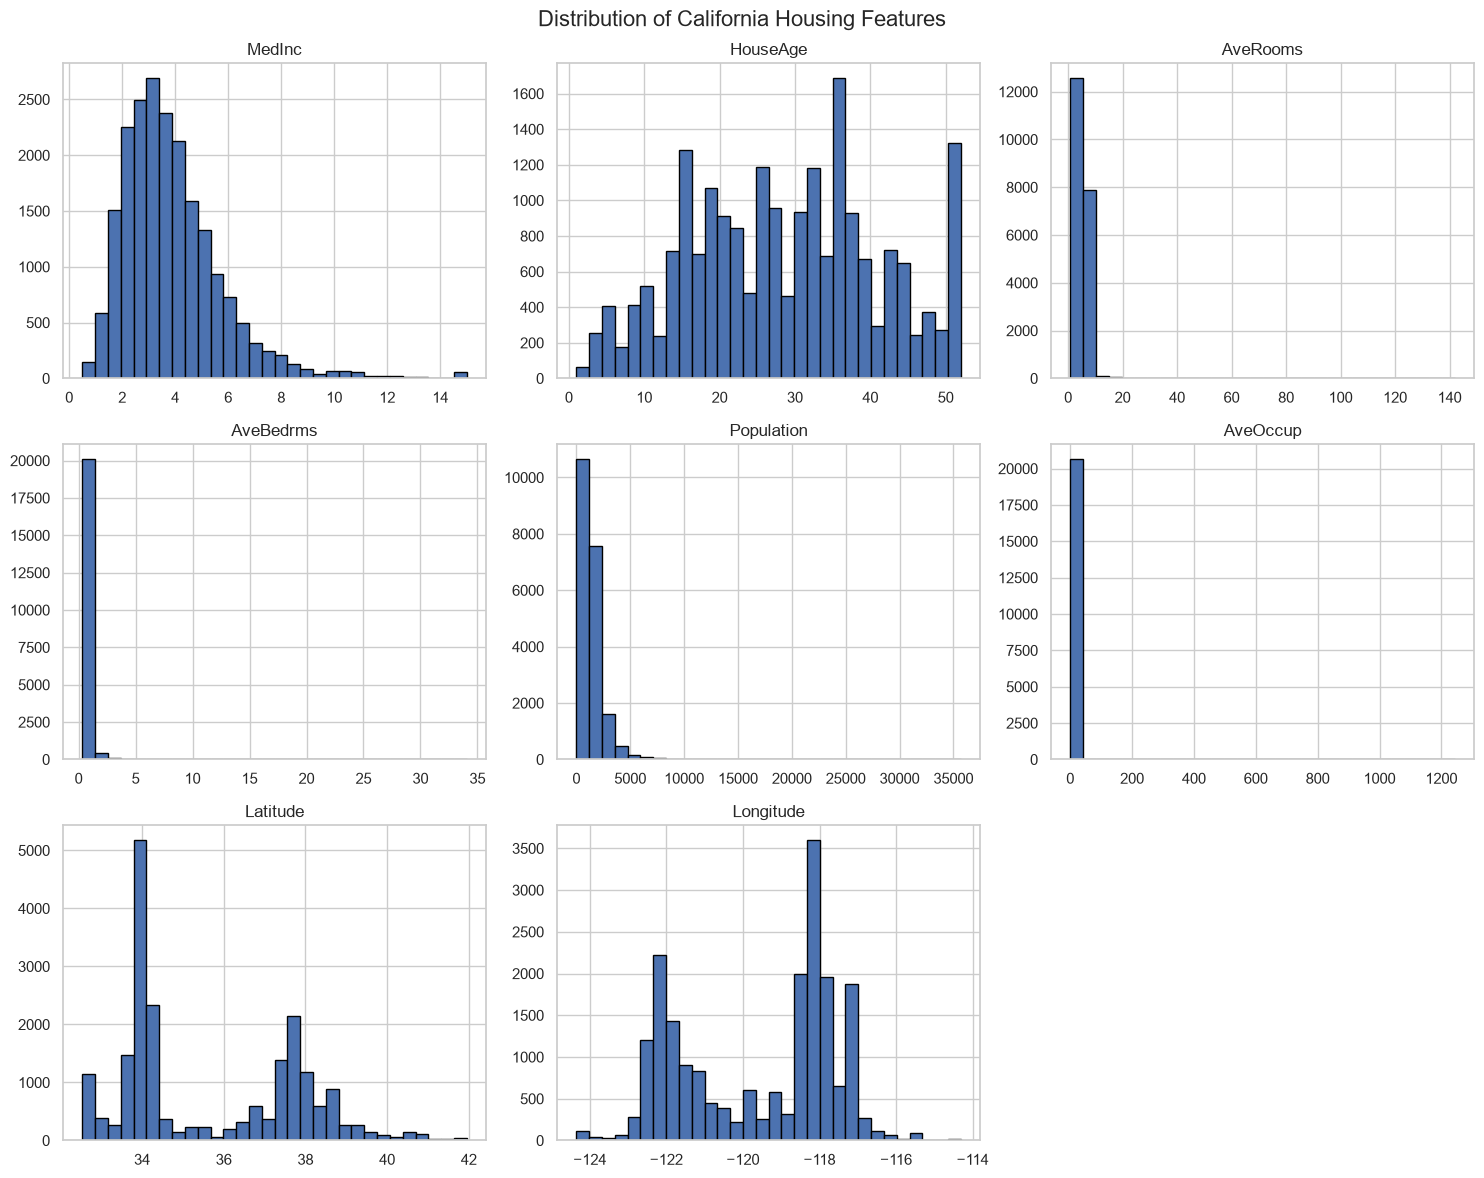

In [10]:
# Select input features
features = X.columns

# Create histograms
X[features].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of California Housing Features", fontsize=16)
plt.tight_layout()
plt.show()

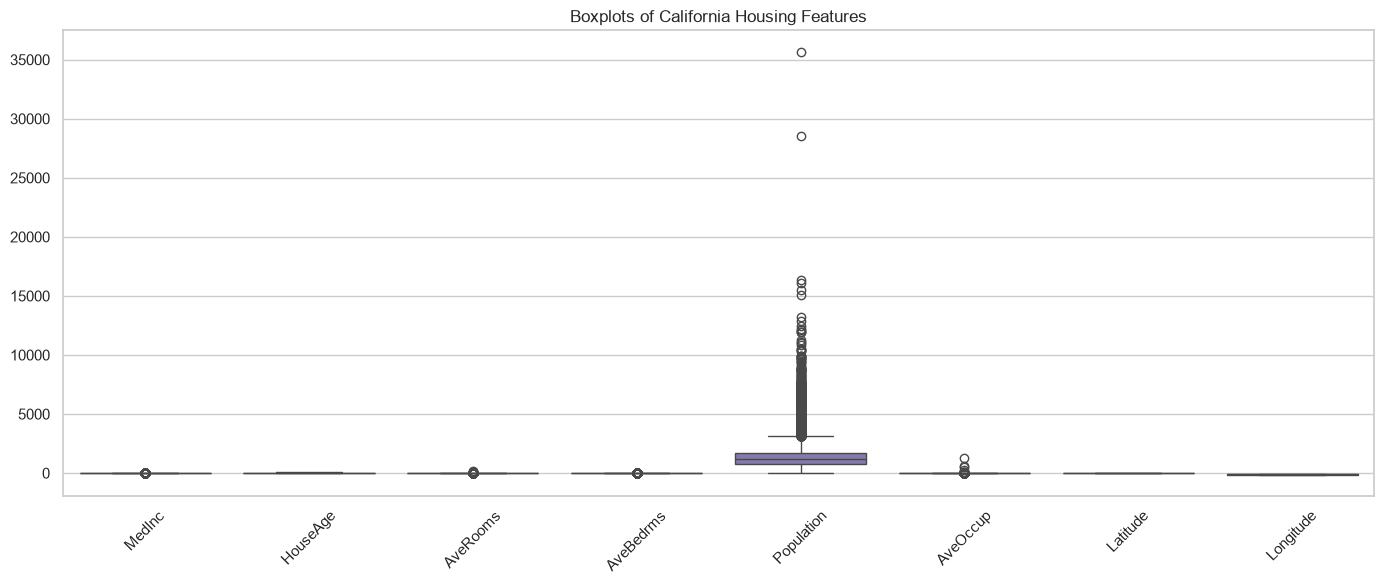

In [11]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.title("Boxplots of California Housing Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

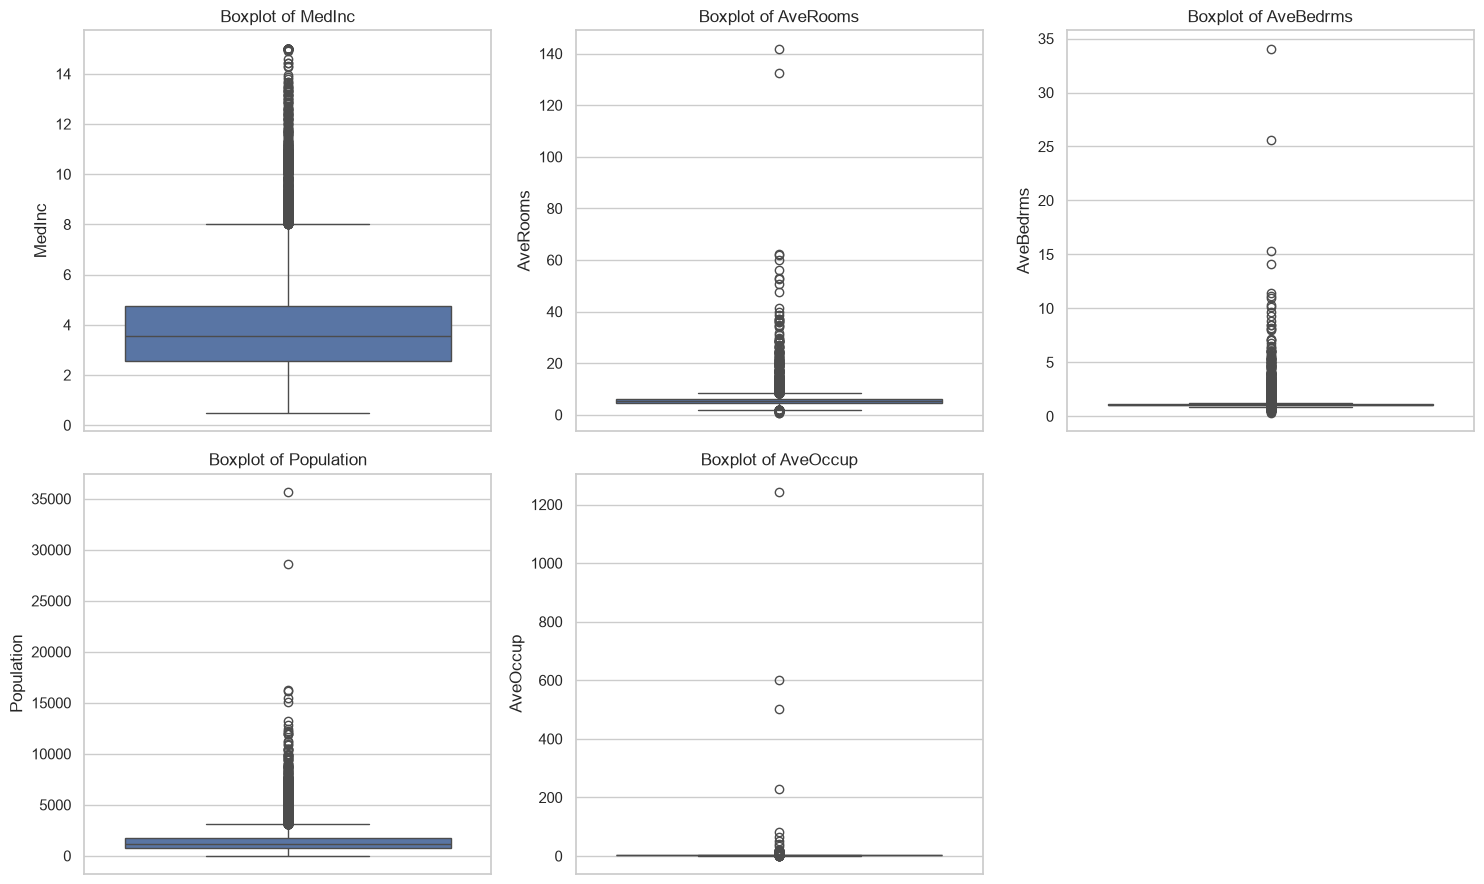

In [12]:
# Select features for closer inspection
selected_features = [
    "MedInc",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup"
]

# Create separate boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, selected_features):
    sns.boxplot(y=X[feature], ax=ax)
    ax.set_title(f"Boxplot of {feature}")

# Remove the unused sixth plot
fig.delaxes(axes.flat[5])

plt.tight_layout()
plt.show()

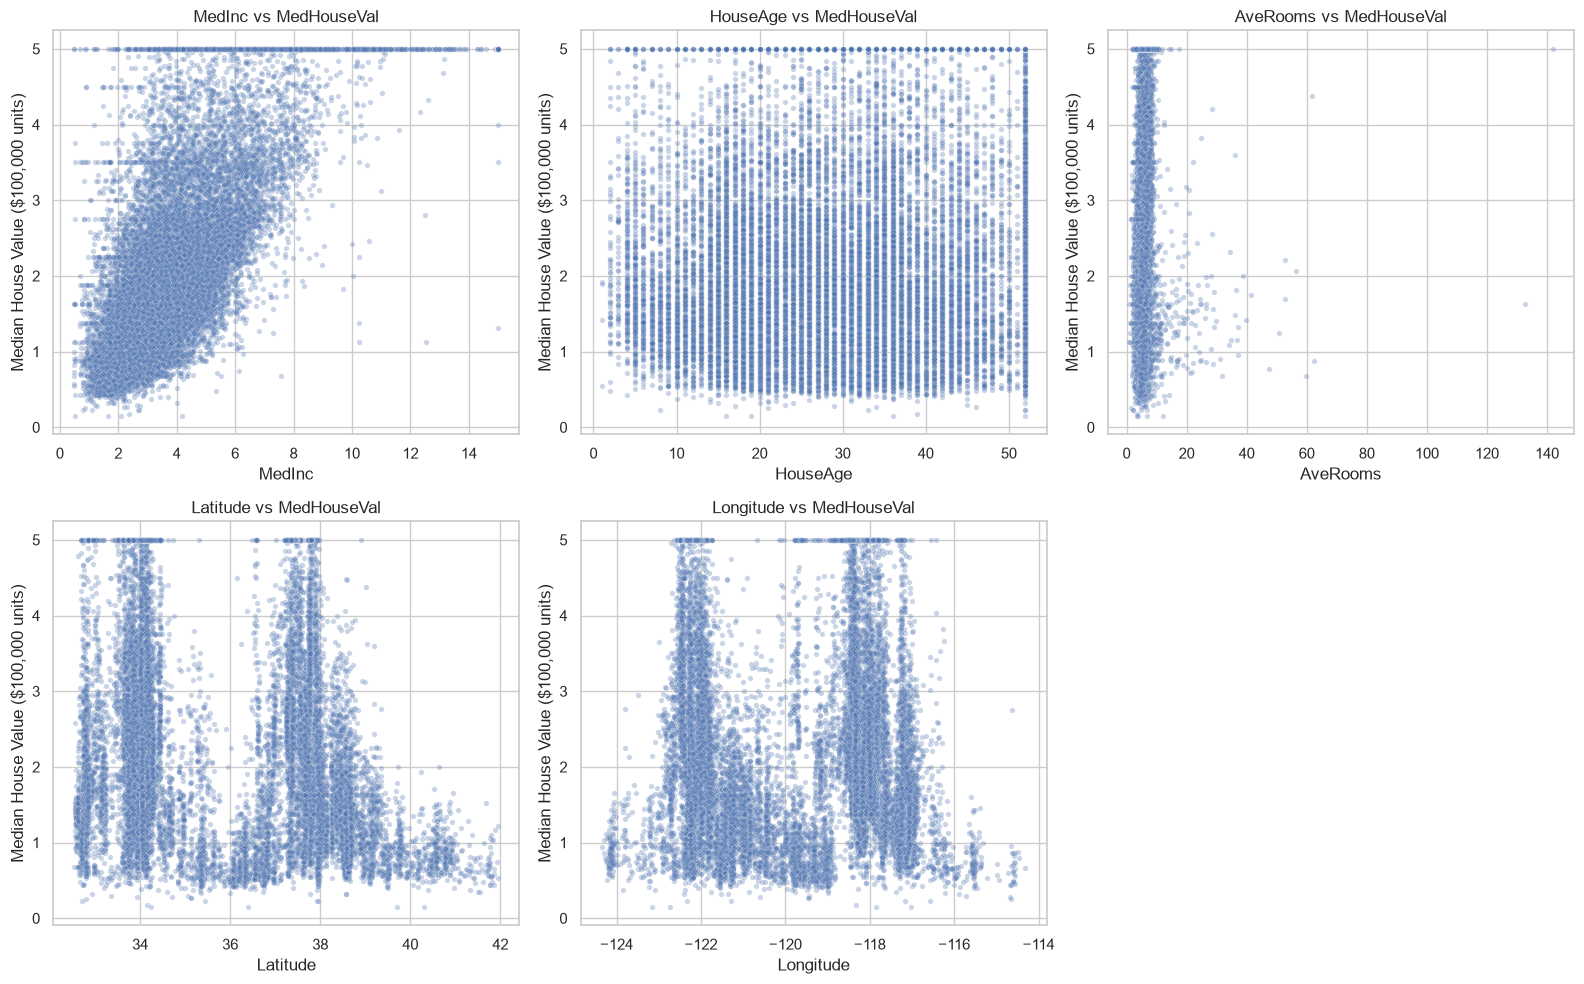

In [13]:
# Select important features to compare with house price
selected_features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "Latitude",
    "Longitude"
]

# Create scatterplots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, feature in zip(axes.flat, selected_features):
    sns.scatterplot(
        x=data[feature],
        y=data["MedHouseVal"],
        alpha=0.3,
        s=15,
        ax=ax
    )
    ax.set_title(f"{feature} vs MedHouseVal")
    ax.set_ylabel("Median House Value ($100,000 units)")

fig.delaxes(axes.flat[5])
plt.tight_layout()
plt.show()

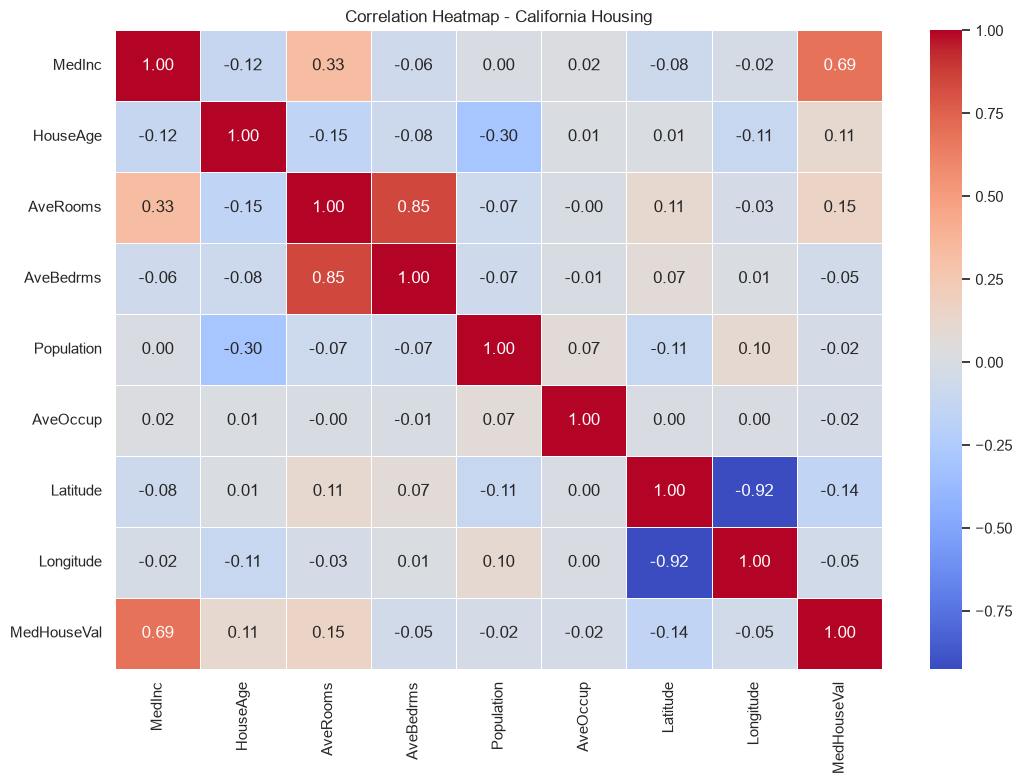

In [14]:
# Calculate correlations between all numeric columns
correlation_matrix = data.corr(numeric_only=True)

# Display correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - California Housing")
plt.tight_layout()
plt.show()